# Economic Factors and Quality of Life: A Global Data Analysis

**Course:** Data Collection & Preparation - SIS project

**Question:** How are economic indicators (GDP per capita, unemployment) and demographic indicators (population, density) related to quality of life (life expectancy) across countries?

**Data sources**
- **API:** World Bank Open Data API — GDP per capita (`NY.GDP.PCAP.CD`), life expectancy (`SP.DYN.LE00.IN`), unemployment (`SL.UEM.TOTL.ZS`), population (`SP.POP.TOTL`), year 2023
- **Web scraping:** Wikipedia, *List of countries and dependencies by population density* (`requests` + `BeautifulSoup`)

**Pipeline:** 1. API collection → 2. Web scraping & cleaning → 3. Merging → 4. EDA → 5. Correlation analysis → 6. Visualization → 7. Optional ML → 8. Conclusions


# 1. Data Collection and Cleaning: World Bank API

Four indicators for 2023 are downloaded from the World Bank API. Regional/income aggregates (e.g. "Arab World") are removed using the API's country metadata, so only real countries and territories remain.

In [3]:
import pandas as pd
import requests
import json
import numpy as np

url = "https://api.worldbank.org/v2/country/all/indicator/NY.GDP.PCAP.CD"

r = requests.get(
    url,
    params={
        "format": "json",
        "date": 2023,
        "per_page": 300
    }
)

r.raise_for_status()

data_gdp = json.loads(r.content.decode("utf-8-sig"))

meta_gdp = data_gdp[0]
records_gdp = data_gdp[1]

df_gdp = pd.DataFrame(records_gdp)

df_gdp.head()

,indicator,country,countryiso3code,date,value,unit,obs_status,decimal
0,"{'id': 'NY.GDP.PCAP.CD', 'value': 'GDP per cap...","{'id': 'ZH', 'value': 'Africa Eastern and Sout...",AFE,2023,1571.132704,,,1
1,"{'id': 'NY.GDP.PCAP.CD', 'value': 'GDP per cap...","{'id': 'ZI', 'value': 'Africa Western and Cent...",AFW,2023,1846.246811,,,1
2,"{'id': 'NY.GDP.PCAP.CD', 'value': 'GDP per cap...","{'id': '1A', 'value': 'Arab World'}",ARB,2023,7504.356377,,,1
3,"{'id': 'NY.GDP.PCAP.CD', 'value': 'GDP per cap...","{'id': 'S3', 'value': 'Caribbean small states'}",CSS,2023,17609.682707,,,1
4,"{'id': 'NY.GDP.PCAP.CD', 'value': 'GDP per cap...","{'id': 'B8', 'value': 'Central Europe and the ...",CEB,2023,22693.950447,,,1


In [4]:
df_gdp.columns

Index(['indicator', 'country', 'countryiso3code', 'date', 'value', 'unit',
       'obs_status', 'decimal'],
      dtype='object')

In [5]:
df_gdp = df_gdp[["countryiso3code", "country", "date", "value", "indicator"]]

df_gdp.head()

,countryiso3code,country,date,value,indicator
0,AFE,"{'id': 'ZH', 'value': 'Africa Eastern and Sout...",2023,1571.132704,"{'id': 'NY.GDP.PCAP.CD', 'value': 'GDP per cap..."
1,AFW,"{'id': 'ZI', 'value': 'Africa Western and Cent...",2023,1846.246811,"{'id': 'NY.GDP.PCAP.CD', 'value': 'GDP per cap..."
2,ARB,"{'id': '1A', 'value': 'Arab World'}",2023,7504.356377,"{'id': 'NY.GDP.PCAP.CD', 'value': 'GDP per cap..."
3,CSS,"{'id': 'S3', 'value': 'Caribbean small states'}",2023,17609.682707,"{'id': 'NY.GDP.PCAP.CD', 'value': 'GDP per cap..."
4,CEB,"{'id': 'B8', 'value': 'Central Europe and the ...",2023,22693.950447,"{'id': 'NY.GDP.PCAP.CD', 'value': 'GDP per cap..."


In [6]:
df_gdp = df_gdp.rename(columns = {
    "countryiso3code" : "iso3",
    "country" : "Country",
    "date" : "year",
    "value" : "gdp_per_capita"
})

df_gdp.head()

,iso3,Country,year,gdp_per_capita,indicator
0,AFE,"{'id': 'ZH', 'value': 'Africa Eastern and Sout...",2023,1571.132704,"{'id': 'NY.GDP.PCAP.CD', 'value': 'GDP per cap..."
1,AFW,"{'id': 'ZI', 'value': 'Africa Western and Cent...",2023,1846.246811,"{'id': 'NY.GDP.PCAP.CD', 'value': 'GDP per cap..."
2,ARB,"{'id': '1A', 'value': 'Arab World'}",2023,7504.356377,"{'id': 'NY.GDP.PCAP.CD', 'value': 'GDP per cap..."
3,CSS,"{'id': 'S3', 'value': 'Caribbean small states'}",2023,17609.682707,"{'id': 'NY.GDP.PCAP.CD', 'value': 'GDP per cap..."
4,CEB,"{'id': 'B8', 'value': 'Central Europe and the ...",2023,22693.950447,"{'id': 'NY.GDP.PCAP.CD', 'value': 'GDP per cap..."


In [7]:
df_gdp["Country"] = df_gdp["Country"].apply(
    lambda x: x["value"] if isinstance(x, dict) else x
)

df_gdp["indicator"] = df_gdp["indicator"].apply(
    lambda x: x["value"] if isinstance(x, dict) else x
)

In [8]:
url = "https://api.worldbank.org/v2/country"

r = requests.get(url,params={"format": "json","per_page": 400})

r.raise_for_status()
print(r.status_code)
countries_data = json.loads(r.content.decode("utf-8-sig"))
countries_records = countries_data[1]

df_countries = pd.DataFrame(countries_records)

200


In [9]:
valid_countries = df_countries[
    df_countries["region"].apply(lambda x: x["id"] != "NA")
]

valid_iso3 = set(valid_countries["id"])

df_gdp = df_gdp[
    df_gdp["iso3"].isin(valid_iso3)
].copy()

In [10]:
df_gdp = df_gdp[["iso3", "Country", "year", "gdp_per_capita"]]

In [11]:
df_gdp.head()

,iso3,Country,year,gdp_per_capita
49,AFG,Afghanistan,2023,413.757895
50,ALB,Albania,2023,9740.702341
51,DZA,Algeria,2023,5370.477235
52,ASM,American Samoa,2023,NaN
53,AND,Andorra,2023,46812.448450


In [12]:
df_gdp.shape

(217, 4)

In [13]:
def get_indicator(code, column_name):
    url = f"https://api.worldbank.org/v2/country/all/indicator/{code}"

    r = requests.get(url, params={"format": "json","date": 2023,"per_page": 300})

    r.raise_for_status()

    data = json.loads(r.content.decode("utf-8-sig"))
    records = data[1]

    df = pd.DataFrame(records)

   
    df = df[df["countryiso3code"].isin(valid_iso3)].copy()

    df["Country"] = df["country"].apply(
        lambda x: x["value"] if isinstance(x, dict) else x
    )

    df = df.rename(columns={
        "countryiso3code": "iso3",
        "date": "year",
        "value": column_name
    })

    df[column_name] = pd.to_numeric(
        df[column_name],
        errors="coerce"
    )

    return df[
        ["iso3", "Country", "year", column_name]
    ]

In [14]:
df_life = get_indicator(
    "SP.DYN.LE00.IN",
    "life_expectancy"
)

df_life.head()

,iso3,Country,year,life_expectancy
49,AFG,Afghanistan,2023,66.035
50,ALB,Albania,2023,79.602
51,DZA,Algeria,2023,76.261
52,ASM,American Samoa,2023,72.852
53,AND,Andorra,2023,84.041


In [15]:
df_unemployment = get_indicator(
    "SL.UEM.TOTL.ZS",
    "unemployment"
)

df_unemployment.head()

,iso3,Country,year,unemployment
49,AFG,Afghanistan,2023,14.008
50,ALB,Albania,2023,10.669
51,DZA,Algeria,2023,11.645
52,ASM,American Samoa,2023,NaN
53,AND,Andorra,2023,NaN


In [16]:
df_population = get_indicator(
    "SP.POP.TOTL",
    "population"
)

df_population.head()

,iso3,Country,year,population
49,AFG,Afghanistan,2023,41454761.0
50,ALB,Albania,2023,2411658.0
51,DZA,Algeria,2023,46164219.0
52,ASM,American Samoa,2023,47521.0
53,AND,Andorra,2023,80856.0


In [17]:
df_economic = df_gdp.merge(
    df_life[["iso3", "life_expectancy"]],
    on="iso3",
    how="left",
    validate="one_to_one"
)

df_economic = df_economic.merge(
    df_unemployment[["iso3", "unemployment"]],
    on="iso3",
    how="left",
    validate="one_to_one"
)

df_economic = df_economic.merge(
    df_population[["iso3", "population"]],
    on="iso3",
    how="left",
    validate="one_to_one"
)

df_economic.head()

,iso3,Country,year,gdp_per_capita,life_expectancy,unemployment,population
0,AFG,Afghanistan,2023,413.757895,66.035,14.008,41454761.0
1,ALB,Albania,2023,9740.702341,79.602,10.669,2411658.0
2,DZA,Algeria,2023,5370.477235,76.261,11.645,46164219.0
3,ASM,American Samoa,2023,NaN,72.852,NaN,47521.0
4,AND,Andorra,2023,46812.448450,84.041,NaN,80856.0


In [18]:
df_economic.shape

(217, 7)

In [19]:
df_economic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 217 entries, 0 to 216
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   iso3             217 non-null    object 
 1   Country          217 non-null    object 
 2   year             217 non-null    object 
 3   gdp_per_capita   204 non-null    float64
 4   life_expectancy  217 non-null    float64
 5   unemployment     184 non-null    float64
 6   population       217 non-null    float64
dtypes: float64(4), object(3)
memory usage: 12.0+ KB


In [20]:
df_economic.isna().sum()

iso3                0
Country             0
year                0
gdp_per_capita     13
life_expectancy     0
unemployment       33
population          0
dtype: int64

In [21]:
df_economic[["gdp_per_capita","life_expectancy","unemployment","population"]].describe()

,gdp_per_capita,life_expectancy,unemployment,population
count,204.000000,217.000000,184.000000,2.170000e+02
mean,22295.539426,73.790943,6.778283,3.704862e+07
std,33559.351447,7.122870,5.520379,1.421754e+08
min,249.795164,54.462000,0.130000,9.816000e+03
25%,2945.926786,68.484000,3.163500,8.263530e+05
50%,7862.027081,74.552000,5.210500,6.623183e+06
75%,30638.403469,79.594000,8.427500,2.641820e+07
max,256799.911212,86.372000,34.610000,1.438070e+09


In [22]:
correlation_matrix = df_economic[["gdp_per_capita","life_expectancy","unemployment"]].corr()

correlation_matrix

,gdp_per_capita,life_expectancy,unemployment
gdp_per_capita,1.000000,0.620409,-0.182598
life_expectancy,0.620409,1.000000,-0.150432
unemployment,-0.182598,-0.150432,1.000000


In [23]:

df_economic["log_gdp"] = np.log10( df_economic["gdp_per_capita"])

In [24]:
df_economic[["log_gdp","life_expectancy","unemployment"]].corr()

,log_gdp,life_expectancy,unemployment
log_gdp,1.000000,0.855143,-0.073837
life_expectancy,0.855143,1.000000,-0.150432
unemployment,-0.073837,-0.150432,1.000000


In [25]:
df_economic.to_csv("world_bank_economic_2023.csv",index=False)

In [26]:
df_economic.head()

,iso3,Country,year,gdp_per_capita,life_expectancy,unemployment,population,log_gdp
0,AFG,Afghanistan,2023,413.757895,66.035,14.008,41454761.0,2.616746
1,ALB,Albania,2023,9740.702341,79.602,10.669,2411658.0,3.988590
2,DZA,Algeria,2023,5370.477235,76.261,11.645,46164219.0,3.730013
3,ASM,American Samoa,2023,NaN,72.852,NaN,47521.0,NaN
4,AND,Andorra,2023,46812.448450,84.041,NaN,80856.0,4.670361


# 2. Web Scraping and Cleaning: Wikipedia

Population, area and density are scraped from Wikipedia with `requests` + `BeautifulSoup`, cleaned (non-breaking spaces, thousands separators, numeric types, country names without brackets) and saved to `wikipedia_countries.csv`.

In [27]:
import requests

url = "https://en.wikipedia.org/wiki/List_of_countries_and_dependencies_by_population_density"
headers = {"User-Agent": "SIS-project"}
response = requests.get(url, headers=headers)
print(response.status_code)

200


In [28]:
from bs4 import BeautifulSoup

soup = BeautifulSoup(response.text, "html.parser")
tables = soup.find_all("table", class_="wikitable")
print(len(tables))

1


In [29]:
table = tables[0]
rows = table.find_all("tr")
print(len(rows))
print(rows[0].text)
print(rows[1].text)

248
Location
Density
Population
Land area
Ref.

/km2
/mi2
km2
mi2


In [30]:
print(rows[2].text)
print(rows[3].text)


 World551408,231,613,070148,940,00057,510,000[b]

 Macau (China)21,82656,530720,2623313



In [31]:
cells = rows[3].find_all(["th", "td"])
print(len(cells))
for c in cells:
    print(repr(c.text))

7
'\xa0Macau (China)'
'21,826'
'56,530'
'720,262'
'33'
'13'
''


In [32]:
data = []
for row in rows[3:]:
    cells = row.find_all(["th", "td"])
    if len(cells) < 5:
        continue
    data.append([cells[0].text, cells[1].text, cells[3].text, cells[4].text])

print(len(data))
print(data[0])

245
['\xa0Macau (China)', '21,826', '720,262', '33']


In [33]:
import pandas as pd

df = pd.DataFrame(data, columns=["Country", "Density", "Population", "Area"])
print(df.head())

              Country Density Population   Area
0       Macau (China)  21,826    720,262     33
1              Monaco  19,428     38,857      2
2           Singapore   8,290  6,110,200    737
3   Hong Kong (China)   7,062  7,414,910  1,050
4      Gibraltar (UK)   5,800     39,329    6.8


In [34]:
df["Country"] = df["Country"].str.replace("\xa0", " ").str.strip()
print(df.head())

             Country Density Population   Area
0      Macau (China)  21,826    720,262     33
1             Monaco  19,428     38,857      2
2          Singapore   8,290  6,110,200    737
3  Hong Kong (China)   7,062  7,414,910  1,050
4     Gibraltar (UK)   5,800     39,329    6.8


In [35]:
for col in ["Density", "Population", "Area"]:
    df[col] = df[col].str.replace(",", "")
    df[col] = pd.to_numeric(df[col], errors="coerce")

print(df.head())
print(df.dtypes)

             Country  Density  Population    Area
0      Macau (China)  21826.0    720262.0    33.0
1             Monaco  19428.0     38857.0     2.0
2          Singapore   8290.0   6110200.0   737.0
3  Hong Kong (China)   7062.0   7414910.0  1050.0
4     Gibraltar (UK)   5800.0     39329.0     6.8
Country        object
Density       float64
Population    float64
Area          float64
dtype: object


In [36]:
print(df.isna().sum())
print(df.duplicated().sum())

Country       0
Density       0
Population    1
Area          0
dtype: int64
0


In [37]:
print(df[df["Population"].isna()])

        Country  Density  Population        Area
244  Antarctica    0.009         NaN  14200000.0


In [38]:
df = df.dropna(subset=["Population"])
print(len(df))

244


In [39]:
print(df[df["Country"].str.contains(r"\(")].shape[0])
print(df[df["Country"].str.contains(r"\(")]["Country"].head(15))

42
0                   Macau (China)
3               Hong Kong (China)
4                  Gibraltar (UK)
10              Sint Maarten (NL)
11                   Bermuda (UK)
13                    Jersey (UK)
14                  Guernsey (UK)
18                     Aruba (NL)
22      Saint Barthélemy (France)
27          Saint Martin (France)
32                   Curaçao (NL)
36               Puerto Rico (US)
40                      Guam (US)
41            Cayman Islands (UK)
53    British Virgin Islands (UK)
Name: Country, dtype: object


In [40]:
df["Country"] = df["Country"].str.replace(r"\s*\(.*?\)", "", regex=True).str.strip()
print(df["Country"].head(15))

0            Macau
1           Monaco
2        Singapore
3        Hong Kong
4        Gibraltar
5     Vatican City
6          Bahrain
7         Maldives
8            Malta
9       Bangladesh
10    Sint Maarten
11         Bermuda
12       Palestine
13          Jersey
14        Guernsey
Name: Country, dtype: object


In [41]:
df.to_csv("wikipedia_countries.csv", index=False)
print(df.shape)

(244, 4)


# 3. Data Integration (merging)


In [42]:
wb = pd.read_csv("world_bank_economic_2023.csv")
print(wb.shape)
print(wb.head())

(217, 8)
  iso3         Country  year  gdp_per_capita  life_expectancy  unemployment  \
0  AFG     Afghanistan  2023      413.757895           66.035        14.008   
1  ALB         Albania  2023     9740.702341           79.602        10.669   
2  DZA         Algeria  2023     5370.477235           76.261        11.645   
3  ASM  American Samoa  2023             NaN           72.852           NaN   
4  AND         Andorra  2023    46812.448450           84.041           NaN   

   population   log_gdp  
0  41454761.0  2.616746  
1   2411658.0  3.988590  
2  46164219.0  3.730013  
3     47521.0       NaN  
4     80856.0  4.670361  


In [43]:
merged = pd.merge(df, wb, on="Country", how="outer", indicator=True)
print(merged["_merge"].value_counts())

_merge
both          180
left_only      64
right_only     37
Name: count, dtype: int64


In [44]:
print(merged[merged["_merge"] == "right_only"]["Country"].tolist())

['Bahamas, The', 'Brunei Darussalam', 'Cabo Verde', 'Channel Islands', 'Congo, Dem. Rep.', 'Congo, Rep.', "Cote d'Ivoire", 'Curacao', 'Czechia', 'Egypt, Arab Rep.', 'Gambia, The', 'Hong Kong SAR, China', 'Iran, Islamic Rep.', "Korea, Dem. People's Rep.", 'Korea, Rep.', 'Kyrgyz Republic', 'Lao PDR', 'Macao SAR, China', 'Micronesia, Fed. Sts.', 'Naoero', 'Puerto Rico (US)', 'Russian Federation', 'Sao Tome and Principe', 'Sint Maarten (Dutch part)', 'Slovak Republic', 'Somalia, Fed. Rep.', 'St. Kitts and Nevis', 'St. Lucia', 'St. Martin (French part)', 'St. Vincent and the Grenadines', 'Syrian Arab Republic', 'Turkiye', 'Venezuela, RB', 'Viet Nam', 'Virgin Islands (U.S.)', 'West Bank and Gaza', 'Yemen, Rep.']


In [45]:
print(merged[merged["_merge"] == "left_only"]["Country"].tolist())

['Akrotiri and Dhekelia', 'Anguilla', 'Bahamas', 'Bonaire', 'Brunei', 'Cape Verde', 'Christmas Island', 'Cocos Islands', 'Congo', 'Cook Islands', 'Curaçao', 'Czech Republic', 'DR Congo', 'Egypt', 'Falkland Islands', 'Federated States of Micronesia', 'Gambia', 'Guernsey', 'Hong Kong', 'Iran', 'Ivory Coast', 'Jersey', 'Kyrgyzstan', 'Laos', 'Macau', 'Montserrat', 'Nauru', 'Niue', 'Norfolk Island', 'North Korea', 'Northern Cyprus', 'Palestine', 'Pitcairn Islands', 'Puerto Rico', 'Russia', 'Saba', 'Saint Barthélemy', 'Saint Helena, Ascension and Tristan da Cunha', 'Saint Kitts and Nevis', 'Saint Lucia', 'Saint Martin', 'Saint Pierre and Miquelon', 'Saint Vincent and the Grenadines', 'Sint Eustatius', 'Sint Maarten', 'Slovakia', 'Somalia', 'Somaliland', 'South Korea', 'South Ossetia', 'Syria', 'São Tomé and Príncipe', 'Taiwan', 'Tokelau', 'Transnistria', 'Turkey', 'U.S. Virgin Islands', 'Vatican City', 'Venezuela', 'Vietnam', 'Wallis and Futuna', 'Western Sahara', 'Yemen', 'Åland']


In [46]:
rename_map = {
    "Bahamas": "Bahamas, The",
    "Brunei": "Brunei Darussalam",
    "Cape Verde": "Cabo Verde",
    "Congo": "Congo, Rep.",
    "DR Congo": "Congo, Dem. Rep.",
    "Curaçao": "Curacao",
    "Czech Republic": "Czechia",
    "Egypt": "Egypt, Arab Rep.",
    "Federated States of Micronesia": "Micronesia, Fed. Sts.",
    "Gambia": "Gambia, The",
    "Hong Kong": "Hong Kong SAR, China",
    "Iran": "Iran, Islamic Rep.",
    "Ivory Coast": "Cote d'Ivoire",
    "Kyrgyzstan": "Kyrgyz Republic",
    "Laos": "Lao PDR",
    "Macau": "Macao SAR, China",
    "Nauru": "Naoero",
    "North Korea": "Korea, Dem. People's Rep.",
    "Palestine": "West Bank and Gaza",
    "Puerto Rico": "Puerto Rico (US)",
    "Russia": "Russian Federation",
    "Saint Kitts and Nevis": "St. Kitts and Nevis",
    "Saint Lucia": "St. Lucia",
    "Saint Martin": "St. Martin (French part)",
    "Saint Vincent and the Grenadines": "St. Vincent and the Grenadines",
    "Sint Maarten": "Sint Maarten (Dutch part)",
    "Slovakia": "Slovak Republic",
    "Somalia": "Somalia, Fed. Rep.",
    "South Korea": "Korea, Rep.",
    "Syria": "Syrian Arab Republic",
    "São Tomé and Príncipe": "Sao Tome and Principe",
    "Turkey": "Turkiye",
    "U.S. Virgin Islands": "Virgin Islands (U.S.)",
    "Venezuela": "Venezuela, RB",
    "Vietnam": "Viet Nam",
    "Yemen": "Yemen, Rep.",
}

df["Country"] = df["Country"].replace(rename_map)
print(len(rename_map))

36


In [47]:
merged = pd.merge(df, wb, on="Country", how="outer", indicator=True)
print(merged["_merge"].value_counts())

_merge
both          216
left_only      28
right_only      1
Name: count, dtype: int64


In [48]:
final = pd.merge(df, wb, on="Country", how="inner")
print(final.shape)
print(final.columns.tolist())

(216, 11)
['Country', 'Density', 'Population', 'Area', 'iso3', 'year', 'gdp_per_capita', 'life_expectancy', 'unemployment', 'population', 'log_gdp']


In [49]:
final = final.rename(columns={
    "Population": "population_wiki",
    "population": "population_wb",
    "Density": "density_km2",
    "Area": "area_km2",
})
print(final.columns.tolist())

['Country', 'density_km2', 'population_wiki', 'area_km2', 'iso3', 'year', 'gdp_per_capita', 'life_expectancy', 'unemployment', 'population_wb', 'log_gdp']


In [50]:
print(final.isna().sum())
print(final.duplicated().sum())
print(final["Country"].duplicated().sum())

Country             0
density_km2         0
population_wiki     0
area_km2            0
iso3                0
year                0
gdp_per_capita     13
life_expectancy     0
unemployment       33
population_wb       0
log_gdp            13
dtype: int64
0
0


In [51]:
final.to_csv("final_dataset.csv", index=False)
print(final.shape)

(216, 11)


# 4. Exploratory Data Analysis (EDA)

**Goal of this part:** understand the merged dataset (World Bank API + Wikipedia scraping), look for patterns between economic and demographic indicators, and visualize the main findings.

Unit of analysis: one row = one country/territory in 2023.

In [52]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats


BLUE, ORANGE, GREY = "#2a6fb0", "#d9822b", "#8a8f98"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.labelsize": 10,
})
os.makedirs("figures", exist_ok=True)

df = pd.read_csv("final_dataset.csv")
print("Shape:", df.shape)
df.head()

Shape: (216, 11)


,Country,density_km2,population_wiki,area_km2,iso3,year,gdp_per_capita,life_expectancy,unemployment,population_wb,log_gdp
0,"Macao SAR, China",21826.0,720262.0,33.0,MAC,2023,67216.363111,83.180488,2.206,678800.0,4.827475
1,Monaco,19428.0,38857.0,2.0,MCO,2023,256799.911212,86.372000,NaN,38956.0,5.409595
2,Singapore,8290.0,6110200.0,737.0,SGP,2023,86382.590050,83.097561,3.444,5917648.0,4.936426
3,"Hong Kong SAR, China",7062.0,7414910.0,1050.0,HKG,2023,50525.111931,85.247317,2.949,7536100.0,4.703507
4,Gibraltar,5800.0,39329.0,6.8,GIB,2023,NaN,83.553000,NaN,38471.0,NaN


In [53]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 216 entries, 0 to 215
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Country          216 non-null    object 
 1   density_km2      216 non-null    float64
 2   population_wiki  216 non-null    float64
 3   area_km2         216 non-null    float64
 4   iso3             216 non-null    object 
 5   year             216 non-null    int64  
 6   gdp_per_capita   203 non-null    float64
 7   life_expectancy  216 non-null    float64
 8   unemployment     183 non-null    float64
 9   population_wb    216 non-null    float64
 10  log_gdp          203 non-null    float64
dtypes: float64(8), int64(1), object(2)
memory usage: 18.7+ KB


### Missing values
Missing values come only from the World Bank side (GDP and unemployment are not reported for some territories). They are not imputed in the EDA: each statistic or plot simply uses the countries that have both values (pairwise deletion), and the number of countries used (`n`) is always shown.

In [54]:
missing = pd.DataFrame({"missing": df.isna().sum(), "percent": (df.isna().mean() * 100).round(1)})
missing = missing[missing["missing"] > 0]
print(missing)
print("\nCountries without GDP per capita:", df.loc[df["gdp_per_capita"].isna(), "Country"].tolist())

                missing  percent
gdp_per_capita       13      6.0
unemployment         33     15.3
log_gdp              13      6.0

Countries without GDP per capita: ['Gibraltar', 'St. Martin (French part)', 'Guam', 'British Virgin Islands', 'Virgin Islands (U.S.)', 'American Samoa', "Korea, Dem. People's Rep.", 'Syrian Arab Republic', 'Northern Mariana Islands', 'Cuba', 'Yemen, Rep.', 'Eritrea', 'South Sudan']


###  Descriptive statistics

In [55]:
num_cols = ["gdp_per_capita", "life_expectancy", "unemployment", "population_wb", "density_km2", "area_km2"]
desc = df[num_cols].describe().T
desc["skew"] = df[num_cols].skew()
desc.round(2)

,count,mean,std,min,25%,50%,75%,max,skew
gdp_per_capita,203.0,22037.95,3.343954e+04,249.80,2925.79,7827.30,29777.07,2.567999e+05,3.40
life_expectancy,216.0,73.76,7.120000e+00,54.46,68.45,74.52,79.00,8.637000e+01,-0.41
unemployment,183.0,6.78,5.540000e+00,0.13,3.15,5.18,8.50,3.461000e+01,2.07
population_wb,216.0,37219363.16,1.424833e+08,9816.00,844378.50,6723398.00,26478633.50,1.438070e+09,8.77
density_km2,216.0,471.71,2.137610e+03,0.03,40.00,97.50,246.00,2.182600e+04,8.39
area_km2,216.0,615823.71,1.784233e+06,2.00,10202.50,92943.00,470625.00,1.712519e+07,5.95


**Observations.**
- Life expectancy is fairly symmetric (mean ≈ 73.8 years, skew ≈ −0.4).
- GDP per capita is strongly right-skewed (skew ≈ 3.4): the median (~$7.8k) is below the mean  (~$22k). Population, area and density are even more skewed (skew 6–9) because of a few giants (China, India) and tiny city-states (Macao, Monaco, Singapore).
- Because of this skew, **log-scale** is used for GDP, population and density in correlations and plots.

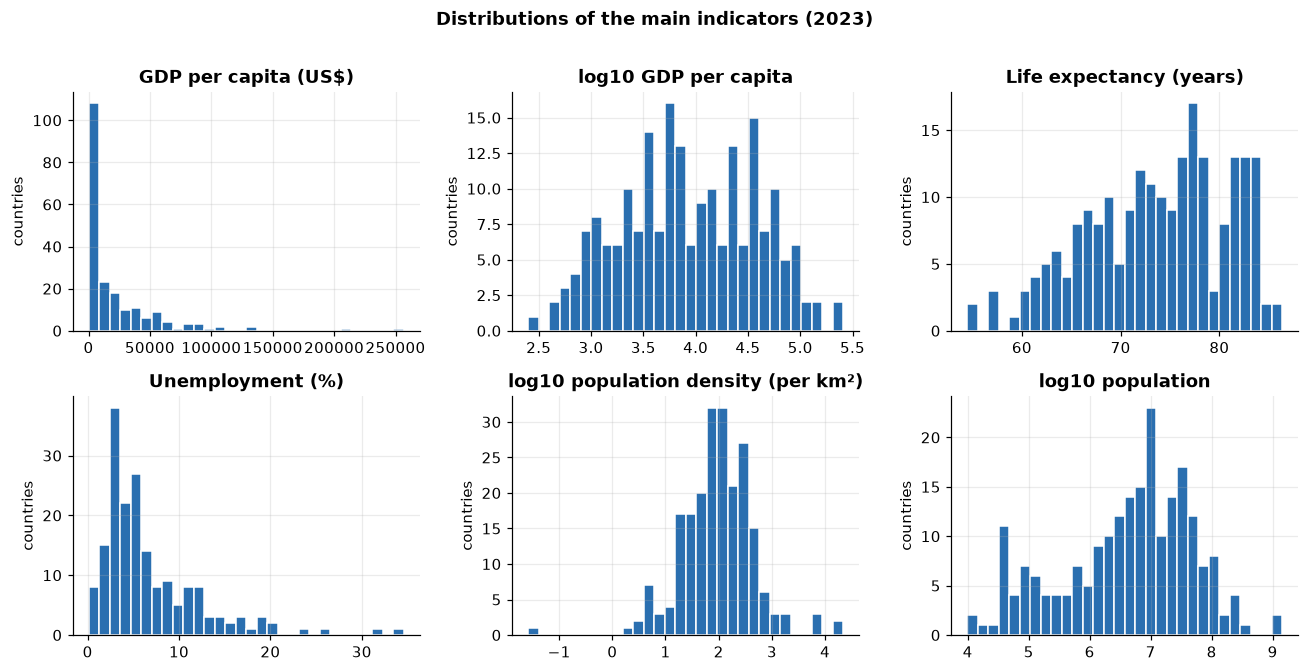

In [57]:
df["log_density"] = np.log10(df["density_km2"])
df["log_population"] = np.log10(df["population_wb"])

fig, axes = plt.subplots(2, 3, figsize=(12, 6))
items = [("gdp_per_capita", "GDP per capita (US$)"), ("log_gdp", "log10 GDP per capita"),
         ("life_expectancy", "Life expectancy (years)"), ("unemployment", "Unemployment (%)"),
         ("log_density", "log10 population density (per km²)"), ("log_population", "log10 population")]
for ax, (c, t) in zip(axes.ravel(), items):
    ax.hist(df[c].dropna(), bins=30, color=BLUE, edgecolor="white")
    ax.set_title(t); ax.set_ylabel("countries")
fig.suptitle("Distributions of the main indicators (2023)", fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig("figures/fig0_distributions.png", bbox_inches="tight")
plt.show()

The raw GDP histogram is heavily skewed; after the log transform it becomes close to symmetric. This is the reason `log_gdp` is used below.

### Extremes

In [58]:
cols = ["Country", "gdp_per_capita", "life_expectancy", "unemployment", "density_km2"]
print("Top 5 life expectancy"); display(df.nlargest(5, "life_expectancy")[cols].round(1))
print("Bottom 5 life expectancy"); display(df.nsmallest(5, "life_expectancy")[cols].round(1))
print("Top 5 GDP per capita"); display(df.nlargest(5, "gdp_per_capita")[cols].round(1))

Top 5 life expectancy


,Country,gdp_per_capita,life_expectancy,unemployment,density_km2
1,Monaco,256799.9,86.4,NaN,19428.0
18,San Marino,59871.3,85.7,NaN,560.0
3,"Hong Kong SAR, China",50525.1,85.2,2.9,7062.0
53,Liechtenstein,206780.6,84.6,NaN,249.0
60,Switzerland,104449.8,84.2,4.0,226.0


Bottom 5 life expectancy


,Country,gdp_per_capita,life_expectancy,unemployment,density_km2
51,Nigeria,2138.8,54.5,3.1,255.0
194,Chad,950.0,55.1,1.1,16.0
127,Lesotho,921.4,57.4,16.3,77.0
203,Central African Republic,496.0,57.4,6.2,8.6
188,South Sudan,NaN,57.6,12.4,19.0


Top 5 GDP per capita


,Country,gdp_per_capita,life_expectancy,unemployment,density_km2
1,Monaco,256799.9,86.4,NaN,19428.0
53,Liechtenstein,206780.6,84.6,NaN,249.0
50,Luxembourg,133230.6,83.3,5.2,261.0
10,Bermuda,132961.8,82.3,NaN,1197.0
130,Ireland,106818.9,82.8,4.2,76.0


### Sanity checks of the integrated data
Two checks that show the merge is trustworthy:
1. Wikipedia density should equal Wikipedia population / area.
2. Wikipedia population vs World Bank population should be close (different sources and reference dates).

In [59]:
dens_calc = df["population_wiki"] / df["area_km2"]
print("Density consistent with population/area (within 5%):",
      (abs(df["density_km2"] / dens_calc - 1) < 0.05).mean().round(3))

ratio = df["population_wiki"] / df["population_wb"]
print("Population Wikipedia / World Bank: median =", ratio.median().round(3),
      "| within ±10% for", f"{((ratio > 0.9) & (ratio < 1.1)).mean():.1%}", "of countries")
display(df.loc[(ratio < 0.9) | (ratio > 1.1), ["Country", "population_wiki", "population_wb"]].round(0))

Density consistent with population/area (within 5%): 0.995
Population Wikipedia / World Bank: median = 1.012 | within ±10% for 95.8% of countries


,Country,population_wiki,population_wb
27,Curacao,185482.0,154654.0
40,Trinidad and Tobago,1507782.0,1367510.0
47,Qatar,3048423.0,2656032.0
55,Virgin Islands (U.S.),84905.0,104917.0
67,Togo,9515236.0,8223850.0
102,Albania,2791765.0,2411658.0
112,Moldova,3034961.0,2457783.0
113,Cuba,9748532.0,11019931.0
198,Paraguay,6109903.0,6844146.0


The two population sources agree for ~96% of countries; the few larger gaps (e.g. Moldova, Albania, Togo) come from different reference years/methods. For analysis we use `population_wb` (same year as the other indicators); `population_wiki` is kept only for this check.

# 5. Correlation Analysis

Pearson measures linear association and is sensitive to outliers; Spearman (rank) is robust and captures monotonic relationships. Because GDP, population and density are heavily skewed, we use their log versions.

Raw GDP vs life expectancy, Pearson r = 0.62
log GDP vs life expectancy, Pearson r = 0.85


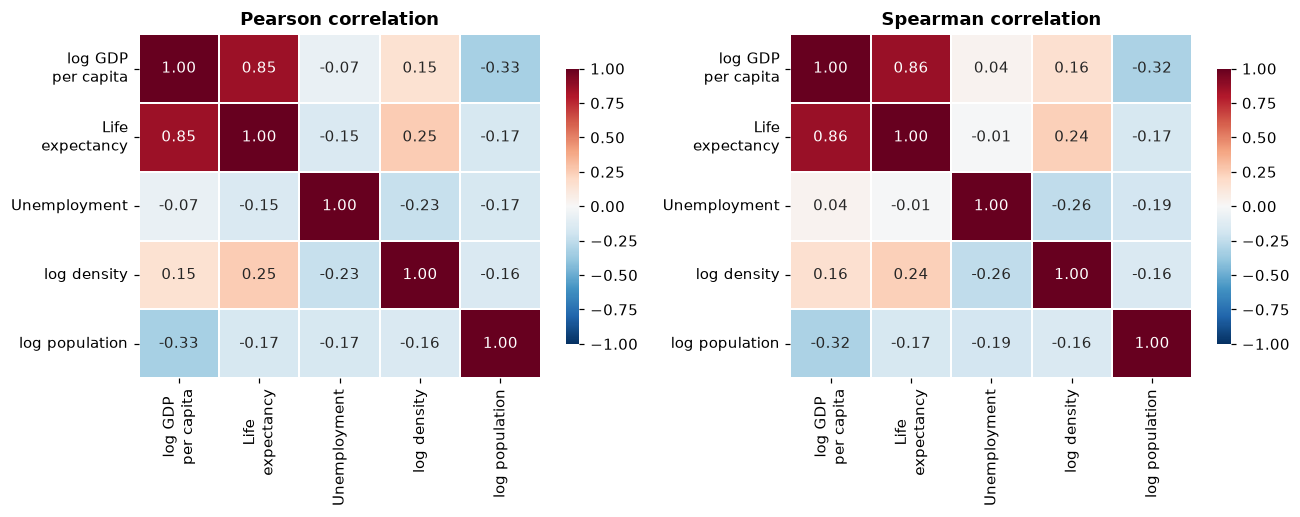

In [60]:
corr_cols = ["log_gdp", "life_expectancy", "unemployment", "log_density", "log_population"]
labels = ["log GDP\nper capita", "Life\nexpectancy", "Unemployment", "log density", "log population"]

print("Raw GDP vs life expectancy, Pearson r =", df[["gdp_per_capita", "life_expectancy"]].corr().iloc[0, 1].round(2))
print("log GDP vs life expectancy, Pearson r =", df[["log_gdp", "life_expectancy"]].corr().iloc[0, 1].round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, method in zip(axes, ["pearson", "spearman"]):
    c = df[corr_cols].corr(method=method)
    sns.heatmap(c, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, center=0,
                xticklabels=labels, yticklabels=labels, linewidths=1, linecolor="white",
                cbar_kws={"shrink": 0.8}, ax=ax)
    ax.set_title(f"{method.capitalize()} correlation")
    ax.grid(False)
plt.tight_layout()
plt.savefig("figures/fig4_correlation_heatmap.png", bbox_inches="tight")
plt.show()

In [61]:
pairs = [("log_gdp", "life_expectancy"), ("log_gdp", "unemployment"), ("unemployment", "life_expectancy"),
         ("log_density", "life_expectancy"), ("log_density", "log_gdp"), ("log_population", "life_expectancy")]
rows = []
for a, b in pairs:
    d = df[[a, b]].dropna()
    r, p = stats.spearmanr(d[a], d[b])
    rows.append({"x": a, "y": b, "n": len(d), "spearman_r": round(r, 2), "p_value": f"{p:.2g}"})
pd.DataFrame(rows)

,x,y,n,spearman_r,p_value
0,log_gdp,life_expectancy,203,0.86,6.6e-62
1,log_gdp,unemployment,175,0.04,0.62
2,unemployment,life_expectancy,183,-0.01,0.89
3,log_density,life_expectancy,216,0.24,0.00034
4,log_density,log_gdp,203,0.16,0.025
5,log_population,life_expectancy,216,-0.17,0.014


**Findings.**
- **Strongest link: GDP per capita ↔ life expectancy.** Raw Pearson r = 0.62, but r = 0.85 after the log transform (Spearman 0.86, p < 0.001): the relationship is strong but *non-linear* — richer countries gain years of life quickly at low income, and more slowly at high income.
- **Unemployment** is almost unrelated to both life expectancy (Spearman ≈ −0.01, not significant) and GDP (≈ 0.04). Cross-country unemployment rates depend on measurement methods and labour-market structure, so they do not reflect the level of development.
- **Density** has a weak positive relation with life expectancy (≈ 0.24) and GDP (≈ 0.16); **population size** has a weak negative one (≈ −0.17). These are weak and partly driven by small wealthy city-states.
- Correlation is not causation: GDP per capita is a proxy for many things (healthcare, nutrition, sanitation, education).

# 6. Visualization

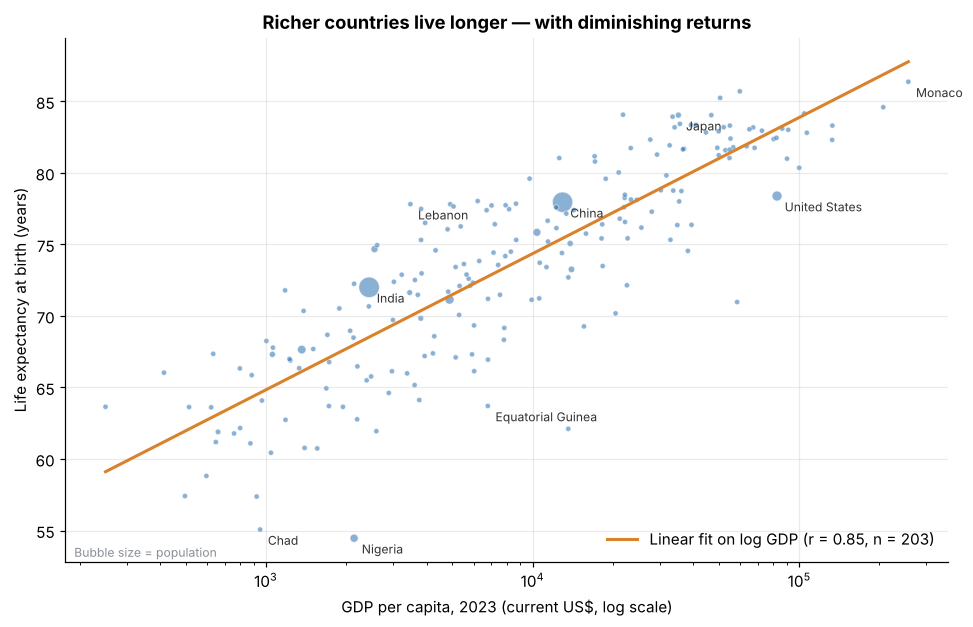

In [59]:
d = df.dropna(subset=["gdp_per_capita"]).copy()
slope, intercept = np.polyfit(d["log_gdp"], d["life_expectancy"], 1)
xs = np.linspace(d["log_gdp"].min(), d["log_gdp"].max(), 100)
r = d["log_gdp"].corr(d["life_expectancy"])

fig, ax = plt.subplots(figsize=(9, 5.8))
ax.scatter(d["gdp_per_capita"], d["life_expectancy"], s=np.clip(d["population_wb"] / 8e6, 12, 400),
           color=BLUE, alpha=0.55, edgecolor="white", linewidth=0.6)
ax.plot(10 ** xs, slope * xs + intercept, color=ORANGE, lw=2, label=f"Linear fit on log GDP (r = {r:.2f}, n = {len(d)})")
ax.set_xscale("log")
for name in ["China", "India", "United States", "Nigeria", "Chad", "Monaco", "Japan", "Lebanon", "Equatorial Guinea"]:
    row = d[d["Country"] == name]
    if len(row):
        ax.annotate(name, (row["gdp_per_capita"].iloc[0], row["life_expectancy"].iloc[0]),
                    xytext=(5, -10), textcoords="offset points", fontsize=8, color="#333")
ax.set_xlabel("GDP per capita, 2023 (current US$, log scale)")
ax.set_ylabel("Life expectancy at birth (years)")
ax.set_title("Richer countries live longer — with diminishing returns")
ax.legend(loc="lower right", frameon=False)
ax.text(0.01, 0.01, "Bubble size = population", transform=ax.transAxes, fontsize=8, color=GREY)
plt.tight_layout()
plt.savefig("figures/fig1_gdp_vs_life_expectancy.png", bbox_inches="tight")
plt.show()

**Figure 1.** Life expectancy rises steeply with GDP per capita at low incomes and flattens at high incomes (hence the log axis). Large countries (China, India) sit close to the trend; Nigeria and Chad are well below it, Lebanon and Sri Lanka well above.

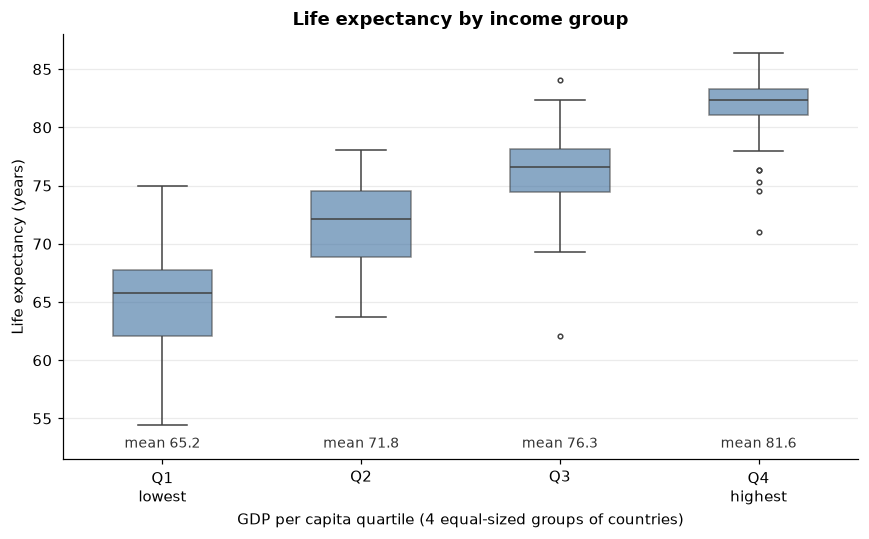

In [62]:
d = df.dropna(subset=["gdp_per_capita"]).copy()
d["gdp_group"] = pd.qcut(d["gdp_per_capita"], 4, labels=["Q1\nlowest", "Q2", "Q3", "Q4\nhighest"])

fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=d, x="gdp_group", y="life_expectancy", color=BLUE, width=0.5, fliersize=3,
            boxprops=dict(alpha=0.6), ax=ax)
means = d.groupby("gdp_group", observed=True)["life_expectancy"].mean()
for i, m in enumerate(means):
    ax.text(i, 52.5, f"mean {m:.1f}", ha="center", fontsize=9, color="#333")
ax.set_ylim(51.5, 88)
ax.set_xlabel("GDP per capita quartile (4 equal-sized groups of countries)")
ax.set_ylabel("Life expectancy (years)")
ax.set_title("Life expectancy by income group")
plt.tight_layout()
plt.savefig("figures/fig2_life_expectancy_by_gdp_quartile.png", bbox_inches="tight")
plt.show()

**Figure 2.** The poorest quarter of countries averages ~65 years, the richest quarter ~82 — a gap of about 16 years. Spread is largest in the middle groups: some mid-income countries do much better or worse than their income suggests.

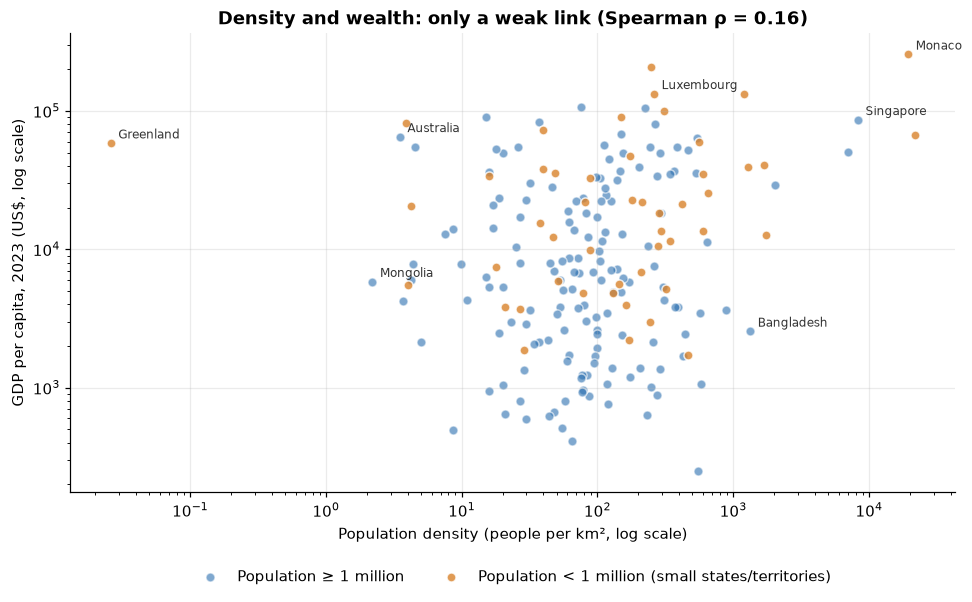

In [63]:
d = df.dropna(subset=["gdp_per_capita"]).copy()
small = d["population_wb"] < 1_000_000
rho, p = stats.spearmanr(d["log_density"], d["log_gdp"])

fig, ax = plt.subplots(figsize=(9, 5.6))
ax.scatter(d.loc[~small, "density_km2"], d.loc[~small, "gdp_per_capita"], s=35, color=BLUE, alpha=0.6,
           edgecolor="white", label="Population ≥ 1 million")
ax.scatter(d.loc[small, "density_km2"], d.loc[small, "gdp_per_capita"], s=35, color=ORANGE, alpha=0.8,
           edgecolor="white", label="Population < 1 million (small states/territories)")
ax.set_xscale("log"); ax.set_yscale("log")
for name in ["Monaco", "Singapore", "Bangladesh", "Mongolia", "Australia", "Luxembourg", "Greenland"]:
    row = d[d["Country"] == name]
    if len(row):
        ax.annotate(name, (row["density_km2"].iloc[0], row["gdp_per_capita"].iloc[0]),
                    xytext=(5, 3), textcoords="offset points", fontsize=8, color="#333")
ax.set_xlabel("Population density (people per km², log scale)")
ax.set_ylabel("GDP per capita, 2023 (US$, log scale)")
ax.set_title(f"Density and wealth: only a weak link (Spearman ρ = {rho:.2f})")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2)
plt.tight_layout()
plt.savefig("figures/fig3_density_vs_gdp.png", bbox_inches="tight")
plt.show()

**Figure 3.** The cloud is wide: both very sparse  and very dense countries can be poor or rich. 

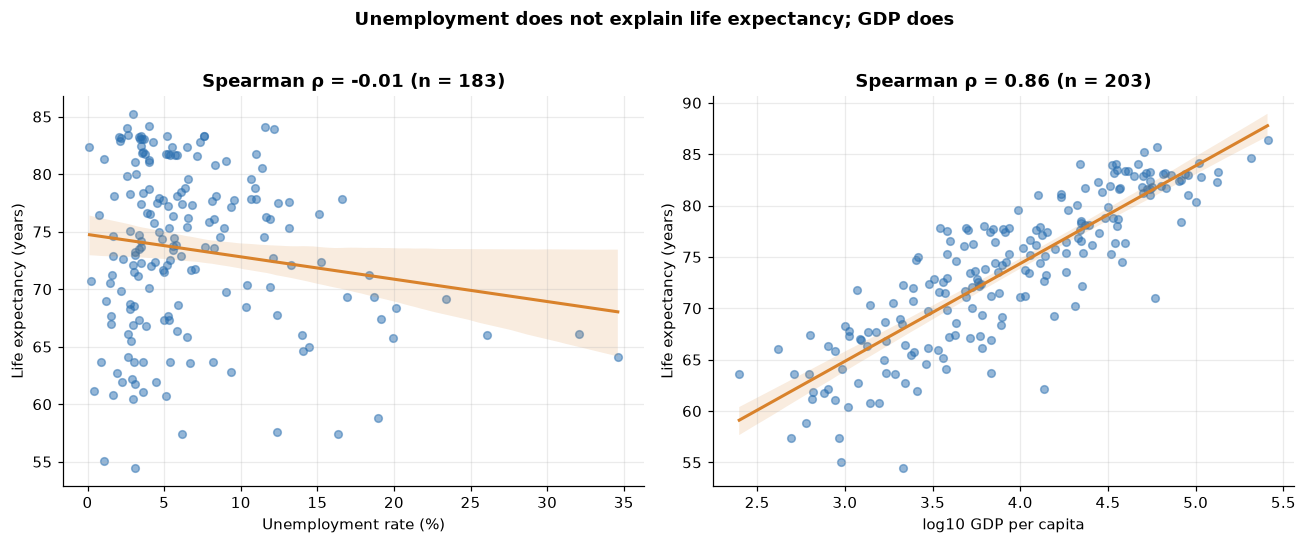

In [64]:
d = df.dropna(subset=["unemployment", "gdp_per_capita"]).copy()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=False)
for ax, (xcol, xl) in zip(axes, [("unemployment", "Unemployment rate (%)"), ("log_gdp", "log10 GDP per capita")]):
    dd = df.dropna(subset=[xcol])
    sns.regplot(data=dd, x=xcol, y="life_expectancy", ax=ax, scatter_kws=dict(s=25, alpha=0.5, color=BLUE),
                line_kws=dict(color=ORANGE, lw=2))
    r_, _ = stats.spearmanr(dd[xcol], dd["life_expectancy"])
    ax.set_xlabel(xl); ax.set_ylabel("Life expectancy (years)")
    ax.set_title(f"Spearman ρ = {r_:.2f} (n = {len(dd)})")
fig.suptitle("Unemployment does not explain life expectancy; GDP does", fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("figures/fig5_unemployment_vs_gdp_life.png", bbox_inches="tight")
plt.show()

**Figure 5.** Side-by-side comparison on the same y-axis: a flat cloud for unemployment vs a clear upward trend for log GDP.

# 7. Optional ML extension: predicting life expectancy

A simple model to check how much of life expectancy can be explained by the indicators we collected. It is an *extension*; the main pipeline above does not depend on it.

- **Target:** `life_expectancy`
- **Features:** log GDP per capita, unemployment, log density, log population
- **Rows:** countries with all features available (rows with missing values are dropped)
- **Model:** Linear Regression, 80/20 train/test split (`random_state=42`), compared with a baseline that always predicts the training mean

In [70]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

features = ["log_gdp", "unemployment", "log_density", "log_population"]
ml = df.dropna(subset=features + ["life_expectancy"])
X, y = ml[features], ml["life_expectancy"]
print("Rows used:", len(ml), "of", len(df))

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

def evaluate(model, cols, name):
    model.fit(X_train[cols], y_train)
    pred = model.predict(X_test[cols])
    return {"model": name, "R2": round(r2_score(y_test, pred), 3),
            "MAE (years)": round(mean_absolute_error(y_test, pred), 2),
            "RMSE (years)": round(mean_squared_error(y_test, pred) ** 0.5, 2)}, pred

res_base, _ = evaluate(DummyRegressor(strategy="mean"), features, "Baseline (mean)")
res_one, _ = evaluate(LinearRegression(), ["log_gdp"], "Linear Regression: log GDP only")
res_all, pred = evaluate(LinearRegression(), features, "Linear Regression: 4 features")
display(pd.DataFrame([res_base, res_one, res_all]))

cv = cross_val_score(LinearRegression(), X, y, cv=5, scoring="r2")
print("5-fold CV R2:", cv.round(2), "| mean =", cv.mean().round(2))
print("Coefficients:", dict(zip(features, LinearRegression().fit(X_train, y_train).coef_.round(2))))

Rows used: 175 of 216


,model,R2,MAE (years),RMSE (years)
0,Baseline (mean),-0.019,5.53,6.51
1,Linear Regression: log GDP only,0.711,2.86,3.47
2,Linear Regression: 4 features,0.736,2.74,3.32


5-fold CV R2: [0.77 0.74 0.68 0.65 0.85] | mean = 0.74
Coefficients: {'log_gdp': np.float64(10.09), 'unemployment': np.float64(-0.08), 'log_density': np.float64(1.09), 'log_population': np.float64(0.3)}


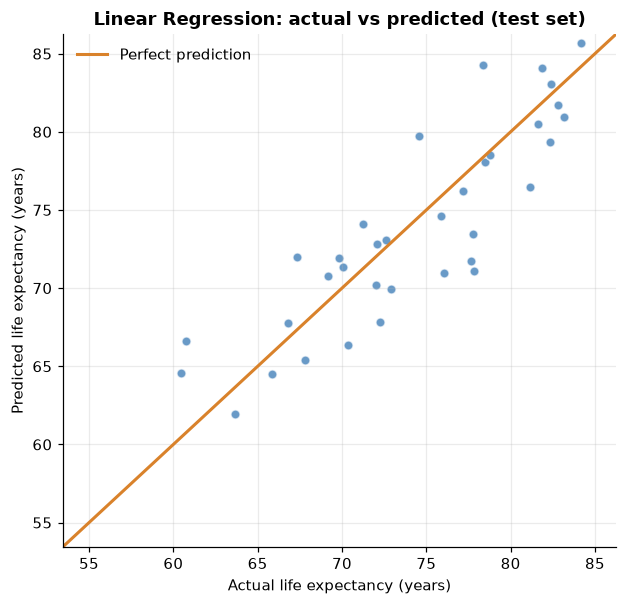

In [71]:
fig, ax = plt.subplots(figsize=(5.8, 5.6))
ax.scatter(y_test, pred, color=BLUE, alpha=0.7, edgecolor="white")
lim = [y.min() - 1, y.max() + 1]
ax.plot(lim, lim, color=ORANGE, lw=2, label="Perfect prediction")
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("Actual life expectancy (years)"); ax.set_ylabel("Predicted life expectancy (years)")
ax.set_title("Linear Regression: actual vs predicted (test set)")
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig("figures/fig6_actual_vs_predicted.png", bbox_inches="tight")
plt.show()

**ML result.** The 4-feature model explains about 74% of the variance on the test set (R² ≈ 0.74, MAE ≈ 2.7 years) versus R² ≈ 0 for the mean baseline, and 5-fold cross-validation gives a similar R² (≈ 0.74), so the result is not a lucky split. Almost all the predictive power comes from **log GDP per capita** (log GDP alone: R² ≈ 0.71); unemployment adds nothing. The model is least accurate for countries whose life expectancy is far from what their income suggests (e.g. Nigeria, Chad). Limitations: small sample (~175 countries), only 2023, linear model, and correlation ≠ causation.

# 8. Conclusions

1. **Data pipeline.** We collected GDP per capita, life expectancy, unemployment and population for 217 economies from the World Bank API and population density/area for 244 locations by scraping Wikipedia. After harmonizing country names (36 manual mappings) 216 countries were merged; 28 Wikipedia-only dependencies (e.g. Anguilla, Falkland Islands) and 1 World Bank aggregate (Channel Islands) have no counterpart.
2. **Main finding.** Economic development and health are strongly linked: log GDP per capita explains most of the variation in life expectancy (r ≈ 0.85). The poorest quarter of countries has ~16 years lower life expectancy than the richest quarter.
3. **The relationship is non-linear.** Raw GDP gives r = 0.62, log GDP gives 0.85 — additional income matters most at low income levels.
4. **Unemployment** and **population density/size** are weakly or not related to life expectancy, so they are poor indicators of quality of life on their own.
5. **ML extension** confirms this: a simple linear model reaches R² ≈ 0.74, almost entirely thanks to log GDP.

**Limitations.** Single year (2023); 13 countries have no GDP and 33 no unemployment value; the sources are from different organizations (reference dates differ slightly); countries and small territories are mixed in one table; cross-sectional correlations cannot show causality.
